# A variational ground-state energy

The variational quantum eigensolver (VQE) prepares a parameterised state, measures the energy of a Hamiltonian from
counts in a few bases, and minimises it classically. The Hamiltonian here is an illustrative two-qubit model with the
structure of the reduced hydrogen-molecule problem used in early VQE experiments (Z, ZZ, XX and YY terms). Its coefficients
are written out below and are not a quantum-chemistry result; its exact ground energy is computed directly for comparison.

In [1]:
from qputwin_demo import *

connect()

QPUTwin at http://localhost:8000: ready, 7 twins reachable


{'status': 'ready',
 'instance': 'c88add07efb8:7:9e791f',
 'job_store': 'ok',
 'backends_reachable': ['quantinuum_helios',
  'ionq_forte',
  'rigetti_ankaa_3',
  'iqm_emerald',
  'ibm_heron',
  'ibm_nighthawk',
  'google_willow']}

## 1. The Hamiltonian

H = g₀ I + g₁ Z₀ + g₂ Z₁ + g₃ Z₀Z₁ + g₄ X₀X₁ + g₅ Y₀Y₁, in energy units we call hartree for the comparison below. Diagonalising its 4×4 matrix gives the exact ground energy the variational result should approach.

In [2]:
G = {"I": -1.0523732, "Z0": 0.3979374, "Z1": -0.3979374, "Z0Z1": -0.0112801, "X0X1": 0.1809312, "Y0Y1": 0.1809312}
I2, X, Y, Z = np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])
def two(a, b):          # operator on q1 (left) and q0 (right), matching count keys "q1 q0"
    return np.kron(b, a)
H = (G["I"] * np.eye(4) + G["Z0"] * two(Z, I2) + G["Z1"] * two(I2, Z) + G["Z0Z1"] * two(Z, Z)
     + G["X0X1"] * two(X, X) + G["Y0Y1"] * two(Y, Y))
E_exact = np.linalg.eigvalsh(H)[0]
print(f"exact ground energy: {E_exact:.6f} Ha")

exact ground energy: -1.915371 Ha


## 2. Energy from counts in three bases

The ansatz cos(θ/2)|01⟩ + sin(θ/2)|10⟩ needs one parameter. Z-basis counts give ⟨Z₀⟩, ⟨Z₁⟩ and ⟨Z₀Z₁⟩; rotating both qubits to the X or Y basis gives ⟨X₀X₁⟩ and ⟨Y₀Y₁⟩.

In [3]:
def ansatz(theta, basis):
    rot = {"Z": [], "X": ["h q[0]", "h q[1]"], "Y": ["sdg q[0]", "h q[0]", "sdg q[1]", "h q[1]"]}[basis]
    return program(2, ["x q[0]", f"ry({theta}) q[1]", "cx q[1],q[0]", *rot])

def expect(counts, bits):
    """<product of Z on the given qubits> from counts with keys 'q1 q0'."""
    total = sum(counts.values())
    return sum(v * (-1) ** sum(int(k[1 - q]) for q in bits) for k, v in counts.items()) / total

def energy(theta, backend="quantinuum_helios", noise=None, shots=20000):
    cz = run(backend, ansatz(theta, "Z"), shots=shots, noise=noise, routing=True)["result"]["counts"]
    cx = run(backend, ansatz(theta, "X"), shots=shots, noise=noise, routing=True, seed=8)["result"]["counts"]
    cy = run(backend, ansatz(theta, "Y"), shots=shots, noise=noise, routing=True, seed=9)["result"]["counts"]
    return (G["I"] + G["Z0"] * expect(cz, [0]) + G["Z1"] * expect(cz, [1]) + G["Z0Z1"] * expect(cz, [0, 1])
            + G["X0X1"] * expect(cx, [0, 1]) + G["Y0Y1"] * expect(cy, [0, 1]))

print(f"E(theta = 0.2) = {energy(0.2):.5f} Ha")

E(theta = 0.2) = -1.74945 Ha


## 3. Scanning the parameter

The ideal energy curve reaches the exact ground energy; device noise on Emerald lifts the whole curve.

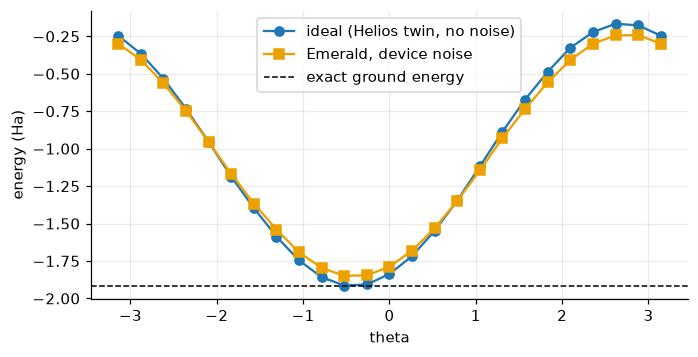

best scanned theta -0.524: E = -1.91402 Ha (exact -1.91537)


In [4]:
thetas = np.linspace(-np.pi, np.pi, 25)
ideal = [energy(t) for t in thetas]
noisy = [energy(t, "iqm_emerald", noise=True) for t in thetas]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(thetas, ideal, "o-", label="ideal (Helios twin, no noise)")
ax.plot(thetas, noisy, "s-", color=COLORS["iqm_emerald"], label="Emerald, device noise")
ax.axhline(E_exact, color="black", ls="--", lw=1, label="exact ground energy")
ax.set_xlabel("theta"); ax.set_ylabel("energy (Ha)"); ax.legend(); plt.show()
theta_best = thetas[int(np.argmin(ideal))]
print(f"best scanned theta {theta_best:.3f}: E = {min(ideal):.5f} Ha (exact {E_exact:.5f})")

## 4. How close each twin gets

At the best parameter, the energy each twin measures under its device noise, against the 1.6 mHa "chemical accuracy" target that VQE studies commonly use.

In [5]:
from scipy.optimize import minimize_scalar
fine = minimize_scalar(lambda t: energy(t, shots=200000), bounds=(theta_best - 0.3, theta_best + 0.3), method="bounded",
                       options={"xatol": 1e-3}).x
rows = []
for b in ALL_BACKENDS:
    E = energy(fine, b, noise=True, shots=50000)
    rows.append({"twin": NAMES[b], "energy (Ha)": round(E, 5), "error (mHa)": round(1000 * (E - E_exact), 2),
                 "within 1.6 mHa": abs(E - E_exact) < 0.0016})
pd.DataFrame(rows).set_index("twin")

,energy (Ha),error (mHa),within 1.6 mHa
twin,,,
Helios,-1.91473,0.64,True
Forte,-1.90001,15.36,False
Ankaa-3,-1.84361,71.76,False
Emerald,-1.85228,63.09,False
Heron r3,-1.91079,4.58,False
Nighthawk,-1.89702,18.35,False
Willow,-1.90378,11.59,False


## Takeaways

- Energies come from counts in three measurement bases, exactly as on hardware.
- Device noise biases the energy upward; the twins show by how much before any hardware time is spent.